In [22]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

# Загрузка данных
df = pd.read_csv('data/cookie_cats.csv')

# Первый взгляд на данные
print("Первые 5 строк:")
print(df.head())

print(f"\nРазмер датасета: {df.shape[0]} строк, {df.shape[1]} колонок")

print("\nРаспределение по группам:")
print(df['version'].value_counts())

print(f"\nДоля группы gate_30: {df['version'].value_counts(normalize=True)['gate_30']:.2%}")
print(f"Доля группы gate_40: {df['version'].value_counts(normalize=True)['gate_40']:.2%}")

Первые 5 строк:
   userid  version  sum_gamerounds  retention_1  retention_7
0     116  gate_30               3        False        False
1     337  gate_30              38         True        False
2     377  gate_40             165         True        False
3     483  gate_40               1        False        False
4     488  gate_40             179         True         True

Размер датасета: 90189 строк, 5 колонок

Распределение по группам:
version
gate_40    45489
gate_30    44700
Name: count, dtype: int64

Доля группы gate_30: 49.56%
Доля группы gate_40: 50.44%


In [23]:
# Считаем долю вернувшихся игроков для каждой метрики и группы
retention_1 = df.groupby('version')['retention_1'].mean()
retention_7 = df.groupby('version')['retention_7'].mean()


print(f'Удержание на 1-й день: {retention_1}')
print(f'Удержание на 7-й день: {retention_7}')

Удержание на 1-й день: version
gate_30    0.448188
gate_40    0.442283
Name: retention_1, dtype: float64
Удержание на 7-й день: version
gate_30    0.190201
gate_40    0.182000
Name: retention_7, dtype: float64


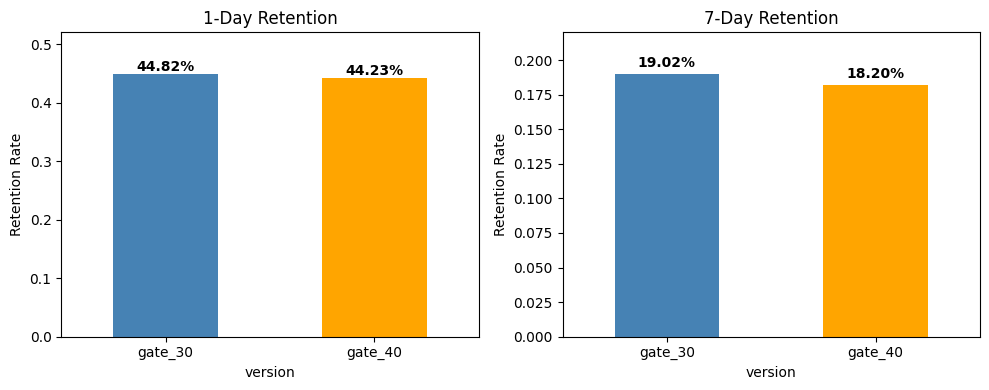

In [24]:
# Строим два графика рядом: для 1-го и 7-го дня
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# График для 1-го дня
ax1 = retention_1.plot(kind='bar', ax=axes[0], color=['steelblue', 'orange'], title='1-Day Retention')
axes[0].set_ylabel('Retention Rate')
axes[0].set_xticklabels(retention_1.index, rotation=0)
for i, v in enumerate(retention_1):
    ax1.text(i, v + 0.005, f'{v:.2%}', ha='center', fontweight='bold')
axes[0].set_ylim(0, 0.52)  # немного места сверху для подписи

# График для 7-го дня
ax2 = retention_7.plot(kind='bar', ax=axes[1], color=['steelblue', 'orange'], title='7-Day Retention')
axes[1].set_ylabel('Retention Rate')
axes[1].set_xticklabels(retention_7.index, rotation=0)
for i, v in enumerate(retention_7):
    ax2.text(i, v + 0.005, f'{v:.2%}', ha='center', fontweight='bold')
axes[1].set_ylim(0, 0.22)

plt.tight_layout()  # чтобы графики не наезжали друг на друга
plt.show()

In [25]:
# Создаём таблицу сопряжённости для 7-дневного удержания
contingency_7 = pd.crosstab(df['version'], df['retention_7'])

chi2, p_value, dof, expected = chi2_contingency(contingency_7)

print(f"Результаты для 7-дневного удержания:")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("Вывод: Разница статистически значима. Перенос ворот влияет на удержание")
else:
    print("Вывод: Разница статистически не значима")

Результаты для 7-дневного удержания:
Chi-square statistic: 9.9591
P-value: 0.001601
Вывод: Разница статистически значима. Перенос ворот влияет на удержание


In [26]:
# Создаём таблицу сопряжённости для 1-дневного удержания
contingency_1 = pd.crosstab(df['version'], df['retention_1'])

chi2_1, p_value_1, dof, expected = chi2_contingency(contingency_1)

print(f"\nРезультаты для 1-дневного удержания:")
print(f"Chi-square statistic: {chi2_1:.4f}")
print(f"P-value: {p_value_1:.6f}")

if p_value_1 < 0.05:
    print("Вывод: Разница статистически значима")
else:
    print("Вывод: Разница статистически не значима")


Результаты для 1-дневного удержания:
Chi-square statistic: 3.1591
P-value: 0.075505
Вывод: Разница статистически не значима
